# What wins football matches? Premier League, La Liga and Champions League, 2022/23

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/uhonglim/football-win-factors/blob/main/analysis.ipynb)

**Question:** which match statistics best explain who wins a game?

**Data:** ESPN's public match data for the 2022/23 season.
- Collected: 380 Premier League, 375 La Liga and 125 Champions League matches (group stage onward).
- ESPN has no team stats for 108 of them (every value is 0), and 6 more can't produce the ratio stats. After removing those we analyse **293 Premier League, 351 La Liga and 123 Champions League matches**.
- Each match becomes two rows, one from each team's point of view.
- Robustness check: all 760 league matches from football-data.co.uk (shots, shots on target, corners, fouls, cards).

**Method**
1. Every stat is turned into a **difference: team minus opponent**. Winning is relative; 15 shots isn't many if the other side has 25.
2. **One stat at a time:** win rate when a team beats its opponent on that stat, and the correlation between the difference and winning.
3. **All stats together:** standardised logistic regression and a random forest with permutation importance, scored by cross-validated AUC.
4. **Season level:** each team's average differences against its points per game. This removes the effect of the score on the stats (teams that lead tend to sit back).

> Goals, assists and saves are left out, because they give away the score (saves = opponent's shots on target minus opponent's goals).

In [1]:
import pandas as pd, numpy as np, json, os
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.inspection import permutation_importance
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

URL = "https://raw.githubusercontent.com/uhonglim/football-win-factors/main/data/matches_2223.csv"
df = pd.read_csv("data/matches_2223.csv") if os.path.exists("data/matches_2223.csv") else pd.read_csv(URL)
# To re-download the data: !python fetch_data.py (see the repo)
print(df.shape)
df.groupby("competition").size().div(2).astype(int).rename("matches")

(1760, 38)


competition
Champions League    125
La Liga             375
Premier League      380
Name: matches, dtype: int64

## 1. Clean up: results, derived stats, differences

In [2]:
# ESPN has all-zero team stats for 108 matches (83 PL, 23 La Liga, 2 UCL). Drop them.
missing = df.groupby("event_id").totalPasses.transform("sum") == 0
print("Matches dropped for missing stats:", (df[missing].groupby("competition").size() // 2).to_dict())
df = df[~missing].copy()

df["result"] = np.select([df.goals > df.goals_against, df.goals < df.goals_against], ["W", "L"], "D")
df["win"] = (df.result == "W").astype(int)
df["points"] = df.result.map({"W": 3, "D": 1, "L": 0})

# Derived ratios (computed here; ESPN rounds its percentages to one decimal)
df["shot_accuracy"] = df.shotsOnTarget / df.totalShots.replace(0, np.nan)
df["pass_accuracy"] = df.accuratePasses / df.totalPasses.replace(0, np.nan)
df["cross_accuracy"] = df.accurateCrosses / df.totalCrosses.replace(0, np.nan)
df["tackle_success"] = df.effectiveTackles / df.totalTackles.replace(0, np.nan)
df["long_ball_share"] = df.totalLongBalls / df.totalPasses.replace(0, np.nan)

FEATURES = {
    "shotsOnTarget": "Shots on target", "totalShots": "Shots", "shot_accuracy": "Shot accuracy",
    "possessionPct": "Possession", "pass_accuracy": "Pass accuracy",
    "totalCrosses": "Crosses", "cross_accuracy": "Cross accuracy", "long_ball_share": "Long-ball share",
    "wonCorners": "Corners", "blockedShots": "Blocked shots", "totalTackles": "Tackles attempted",
    "tackle_success": "Tackle success", "interceptions": "Interceptions", "totalClearance": "Clearances",
    "foulsCommitted": "Fouls", "yellowCards": "Yellow cards", "redCards": "Red cards", "offsides": "Offsides",
}
F = list(FEATURES)
# Total passes correlates 0.96 with possession, so only possession is kept.

# Opponent's stats from the same match -> differences
opp = df[["event_id", "team"] + F].rename(columns={"team": "opponent", **{f: f + "_opp" for f in F}})
df = df.merge(opp, on=["event_id", "opponent"])
for f in F:
    df[f + "_diff"] = df[f] - df[f + "_opp"]
D = [f + "_diff" for f in F]
COMPS = ["Premier League", "La Liga", "Champions League"]
LEAGUES = ["Premier League", "La Liga"]
df = df.dropna(subset=D).reset_index(drop=True)
print(df.shape)
(df.groupby("competition").result.value_counts(normalize=True).unstack()[["W", "D", "L"]] * 100).round(1)

Matches dropped for missing stats: {'Champions League': 2, 'La Liga': 23, 'Premier League': 83}
(1534, 82)


result,W,D,L
competition,,,
Champions League,39.8,20.3,39.8
La Liga,37.7,24.5,37.7
Premier League,38.6,22.9,38.6


## 2. One stat at a time: which head-to-head matters most?

For each stat, the win rate of a team that has **more of it than its opponent**. The baseline win rate is about 38%, since draws are possible.

In [3]:
def battle_table(d):
    rows = []
    for f in F:
        more = d[d[f + "_diff"] > 0]; less = d[d[f + "_diff"] < 0]
        rows.append({"feature": f, "stat": FEATURES[f],
                     "win_more": more.win.mean(), "win_less": less.win.mean(),
                     "ppg_more": more.points.mean(),
                     "r_win": d[f + "_diff"].corr(d.win),
                     "r_gd": d[f + "_diff"].corr(d.goals - d.goals_against)})
    return pd.DataFrame(rows).sort_values("r_win", key=abs, ascending=False)

battle = {c: battle_table(df[df.competition == c]) for c in COMPS}
battle["All"] = battle_table(df)
battle["Both leagues"] = battle_table(df[df.competition.isin(LEAGUES)])
battle["All"].style.format({c: "{:.3f}" for c in battle["All"].columns[2:]}).background_gradient(subset=["r_win"], cmap="RdBu", vmin=-.5, vmax=.5)

,feature,stat,win_more,win_less,ppg_more,r_win,r_gd
0,shotsOnTarget,Shots on target,0.629,0.139,2.120,0.495,0.655
2,shot_accuracy,Shot accuracy,0.537,0.233,1.842,0.325,0.404
1,totalShots,Shots,0.512,0.254,1.770,0.316,0.422
16,redCards,Red cards,0.132,0.581,0.682,-0.183,-0.202
5,totalCrosses,Crosses,0.325,0.448,1.201,-0.144,-0.091
3,possessionPct,Possession,0.430,0.337,1.523,0.121,0.228
13,totalClearance,Clearances,0.438,0.329,1.546,0.117,0.036
4,pass_accuracy,Pass accuracy,0.443,0.325,1.562,0.108,0.201
9,blockedShots,Blocked shots,0.424,0.346,1.501,0.099,0.155
6,cross_accuracy,Cross accuracy,0.404,0.365,1.442,0.089,0.093


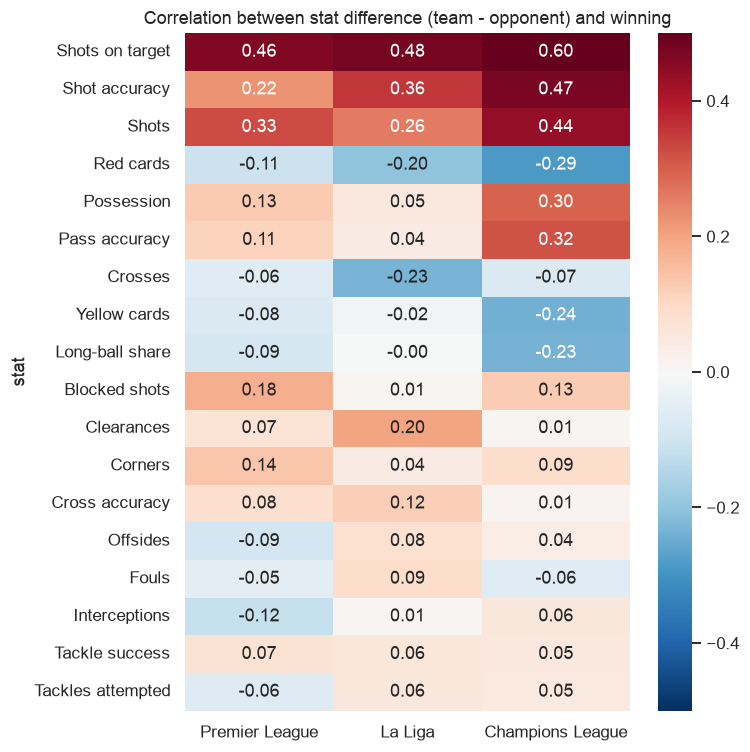

In [4]:
corr = pd.DataFrame({c: battle[c].set_index("stat")["r_win"] for c in COMPS})
corr = corr.loc[corr.abs().mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.5, vmax=.5, ax=ax)
ax.set_title("Correlation between stat difference (team - opponent) and winning")
plt.tight_layout(); plt.show()

**What this shows**
- **Shots on target is far ahead of everything else:** correlation with winning is 0.46 (PL), 0.48 (La Liga) and 0.60 (UCL). Teams with more shots on target than their opponent win 61% to 73% of the time.
- **Shot accuracy** and **total shots** come next (r around 0.3).
- **Possession barely matters in the leagues** (0.13 PL, 0.05 La Liga). Teams with more of the ball win only 38% to 46% of the time. It matters more in the **Champions League (0.30)**, where the gap between teams is wider.
- **More crosses goes with losing** (teams that out-cross their opponent win 33%). Teams that are behind tend to hit a lot of balls into the box.
- **Red cards** hurt in every competition.

## 3. All stats together: which ones still matter after accounting for the rest?

In [5]:
def fit_models(d, feats):
    X, y = d[feats].values, d.win.values
    cv = StratifiedKFold(5, shuffle=True, random_state=42)
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))
    auc_lr = cross_val_score(lr, X, y, cv=cv, scoring="roc_auc").mean()
    lr.fit(X, y)
    coef = pd.Series(lr[-1].coef_[0], index=feats)
    rf = RandomForestClassifier(400, min_samples_leaf=10, random_state=42, n_jobs=-1)
    auc_rf = cross_val_score(rf, X, y, cv=cv, scoring="roc_auc").mean()
    rf.fit(X, y)
    pi = permutation_importance(rf, X, y, n_repeats=10, random_state=42, scoring="roc_auc")
    imp = pd.Series(pi.importances_mean, index=feats)
    return dict(auc_lr=auc_lr, auc_rf=auc_rf, coef=coef, imp=imp)

models = {c: fit_models(df[df.competition == c], D) for c in COMPS}
models["All"] = fit_models(df, D)
pd.DataFrame({k: {"Logistic AUC": v["auc_lr"], "Random forest AUC": v["auc_rf"]} for k, v in models.items()}).round(3)

,Premier League,La Liga,Champions League,All
Logistic AUC,0.822,0.884,0.913,0.871
Random forest AUC,0.802,0.853,0.868,0.851


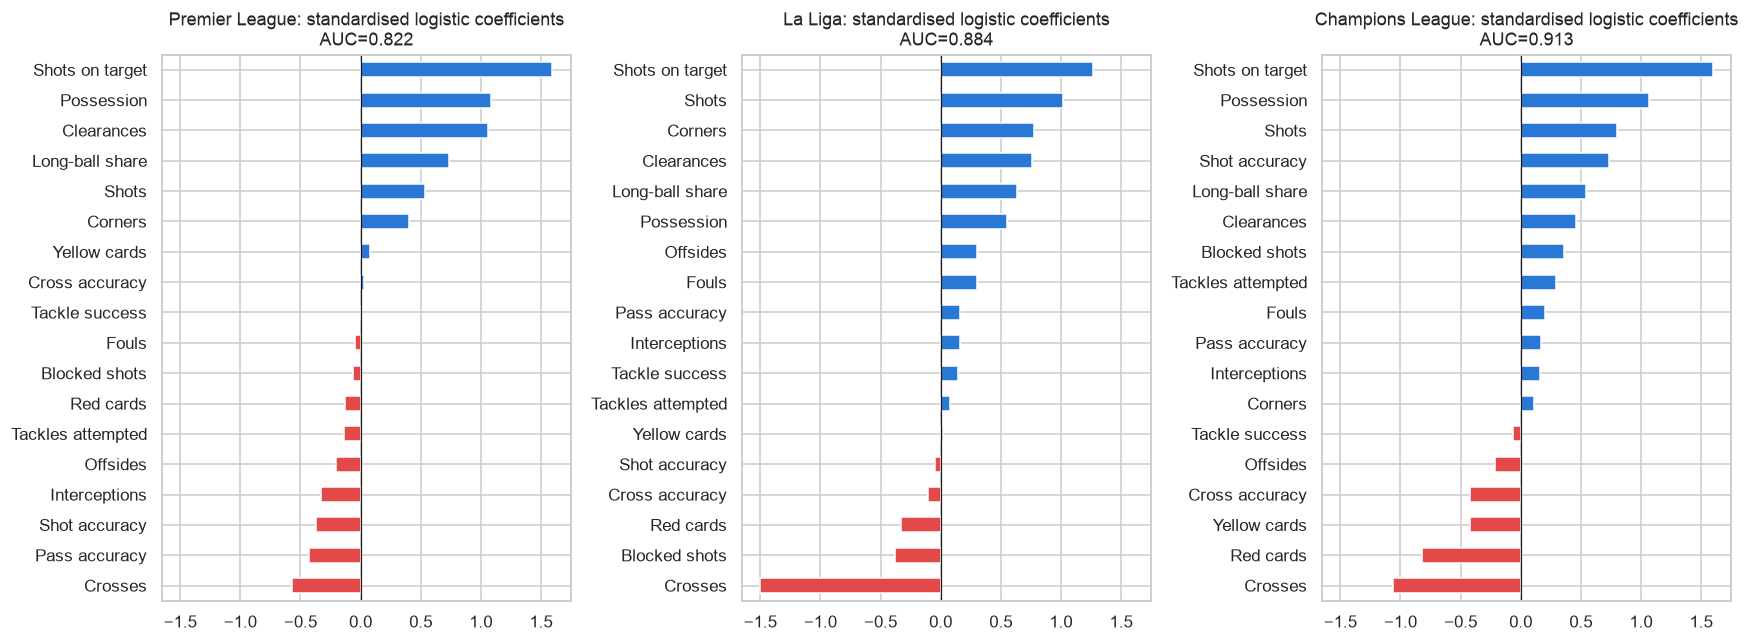

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharex=True)
for ax, c in zip(axes, COMPS):
    s = models[c]["coef"].rename(lambda x: FEATURES[x[:-5]]).sort_values()
    s.plot.barh(ax=ax, color=np.where(s > 0, "#2a78d6", "#e34948"))
    ax.set_title(f"{c}: standardised logistic coefficients\nAUC={models[c]['auc_lr']:.3f}")
    ax.axvline(0, color="k", lw=.8)
plt.tight_layout(); plt.show()

**Reading the coefficients:** each one is the change in the log-odds of winning when that difference rises by one standard deviation, with the other stats held fixed.

- **Shots on target** has the largest positive coefficient in all three competitions. In the random forest its permutation importance (about 0.14) is 2 to 4 times the next stat.
- **Possession** turns positive once shots are accounted for (about +1): with the same shots, the side with more of the ball wins more often.
- **Crosses** has the largest negative coefficient. Lots of crosses is a sign of a team chasing the game.
- **Clearances and long-ball share** are positive because teams that lead defend deep and clear the ball. Here the score drives the stat, not the other way round.
- **Red cards** are negative everywhere, most of all in the Champions League.
- Match stats alone (no goals) reach an AUC of 0.82 to 0.91.

## 4. Without the shooting stats: what else matters?

Shots on target and goals are close to the same thing. Removing all the shooting stats shows which other stats still predict the result.

In [7]:
SHOOT = {"shotsOnTarget_diff", "totalShots_diff", "shot_accuracy_diff", "blockedShots_diff"}
P = [f for f in D if f not in SHOOT]
proc = {c: fit_models(df[df.competition == c], P) for c in COMPS}
proc["All"] = fit_models(df, P)
print({k: round(v["auc_lr"], 3) for k, v in proc.items()})
pd.DataFrame({k: v["coef"].rename(lambda x: FEATURES[x[:-5]]) for k, v in proc.items()}).sort_values("All").round(2)

{'Premier League': np.float64(0.71), 'La Liga': np.float64(0.794), 'Champions League': np.float64(0.803), 'All': np.float64(0.77)}


,Premier League,La Liga,Champions League,All
Crosses,-0.72,-1.47,-1.36,-1.24
Red cards,-0.22,-0.53,-0.82,-0.47
Yellow cards,-0.16,-0.16,-0.75,-0.24
Interceptions,-0.14,0.04,0.17,0.00
Offsides,-0.20,0.32,0.08,0.08
Cross accuracy,0.14,0.17,0.12,0.13
Tackles attempted,-0.01,0.18,0.36,0.14
Tackle success,0.20,0.14,0.11,0.14
Fouls,0.01,0.35,0.37,0.21
Clearances,0.75,0.47,0.38,0.43


Without shooting stats the AUC drops from 0.87 to 0.77. Shooting is the last step that turns play into wins.
Among the rest, **corners, possession, long-ball share and clearances** are positive, and **crosses and red cards** are negative.
Many clearances and few crosses mostly describe the **state of the game** (the leading side defends, the trailing side crosses), so cause and effect run backwards.
To remove that effect, the next step looks at **whole seasons**.

## 5. Season level: which stats put teams at the top of the table?

Single-match stats follow the score (a team that leads sits back). Season averages smooth that out.
We correlate each team's **average difference per match** with its **points per game** (20 PL teams + 20 La Liga teams).

In [8]:
lg = df[df.competition.isin(LEAGUES)]
team = lg.groupby(["competition", "team"]).agg(ppg=("points", "mean"), gf=("goals", "mean"), ga=("goals_against", "mean"),
                                              **{f: (f, "mean") for f in D})
season_corr = pd.DataFrame({
    "Premier League": team.loc["Premier League"][D].corrwith(team.loc["Premier League"].ppg),
    "La Liga": team.loc["La Liga"][D].corrwith(team.loc["La Liga"].ppg),
    "Both leagues": team[D].corrwith(team.ppg)}).rename(lambda x: FEATURES[x[:-5]])
season_corr.sort_values("Both leagues", ascending=False).round(2)

,Premier League,La Liga,Both leagues
Shots on target,0.78,0.88,0.82
Shots,0.71,0.77,0.73
Possession,0.63,0.76,0.68
Pass accuracy,0.62,0.71,0.65
Blocked shots,0.57,0.58,0.57
Corners,0.54,0.58,0.56
Tackle success,0.16,0.62,0.37
Crosses,0.46,0.09,0.31
Shot accuracy,0.14,0.37,0.23
Cross accuracy,0.12,-0.06,0.05


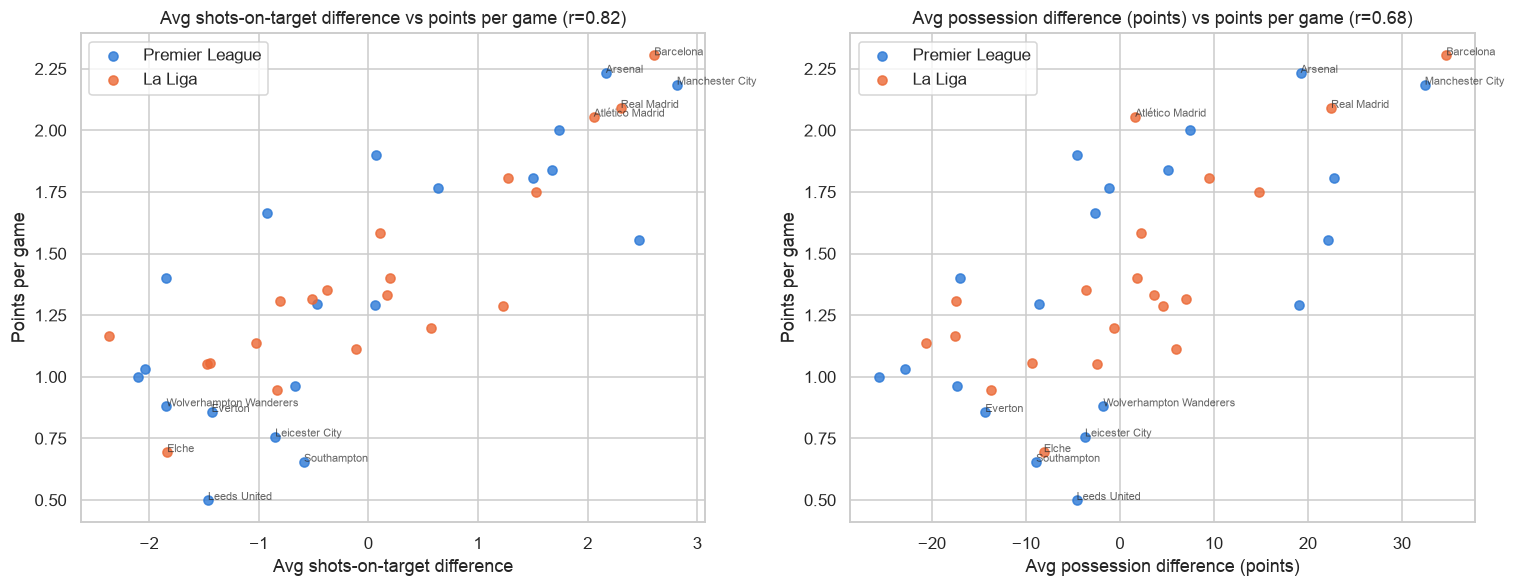

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (x, label) in zip(axes, [("shotsOnTarget_diff", "Avg shots-on-target difference"), ("possessionPct_diff", "Avg possession difference (points)")]):
    for c, col in [("Premier League", "#2a78d6"), ("La Liga", "#eb6834")]:
        t = team.loc[c]
        ax.scatter(t[x], t.ppg, label=c, color=col, alpha=.8)
        for name, r in t.iterrows():
            if r.ppg > 2.0 or r.ppg < .9: ax.annotate(name, (r[x], r.ppg), fontsize=7, alpha=.7)
    ax.set_xlabel(label); ax.set_ylabel("Points per game"); ax.legend()
    ax.set_title(f"{label} vs points per game (r={team[x].corr(team.ppg):.2f})")
plt.tight_layout(); plt.show()

**The twist:** in a single match, possession correlates with winning at only 0.12 (all competitions). Over a season, the possession difference correlates with points per game at **0.68**.
Strong teams have more of the ball all season; they just give it up in matches where they are already ahead.
- At season level the strongest stat is still **shots on target (r = 0.82)**, then shots (0.73), possession (0.68) and pass accuracy (0.65).
- **Interceptions (-0.66), long-ball share (-0.63), tackles attempted (-0.51) and clearances (-0.48)** are negative: weaker teams spend the season defending and clearing.

So **possession marks a strong team; shots on target win the match.**

## 6. Home advantage and the shots-on-target curve

In [10]:
home = df.groupby(["competition", "home"]).win.mean().unstack().rename(columns={0: "away_win", 1: "home_win"})
home["home_edge_pp"] = (home["home_win"] - home["away_win"]) * 100
home.round(3)

home,away_win,home_win,home_edge_pp
competition,,,
Champions League,0.301,0.496,19.512
La Liga,0.276,0.479,20.228
Premier League,0.290,0.481,19.113


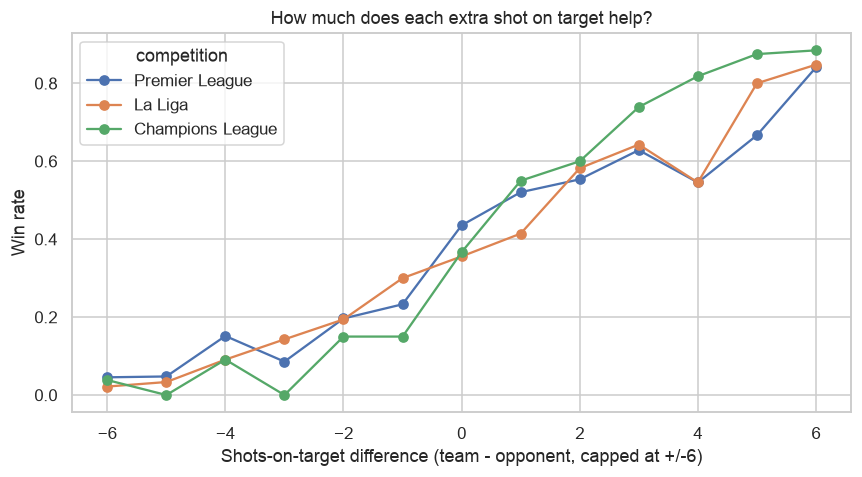

competition,Champions League,La Liga,Premier League,All
sot_bin,,,,
-6.0,0.04,0.02,0.05,0.03
-5.0,0.00,0.03,0.05,0.03
-4.0,0.09,0.09,0.15,0.11
-3.0,0.00,0.14,0.09,0.09
-2.0,0.15,0.19,0.20,0.19
-1.0,0.15,0.30,0.23,0.25
0.0,0.37,0.36,0.44,0.38
1.0,0.55,0.41,0.52,0.48
2.0,0.60,0.58,0.55,0.57


In [11]:
# Win rate by shots-on-target difference, capped at +/-6
df["sot_bin"] = df.shotsOnTarget_diff.clip(-6, 6)
curve = df.groupby(["competition", "sot_bin"]).win.mean().unstack(0)
curve["All"] = df.groupby("sot_bin").win.mean()
counts = df.groupby("sot_bin").size()
ax = curve[COMPS].plot(marker="o", figsize=(8, 4.5))
ax.set_xlabel("Shots-on-target difference (team - opponent, capped at +/-6)"); ax.set_ylabel("Win rate")
ax.set_title("How much does each extra shot on target help?")
plt.tight_layout(); plt.show()
curve.round(2)

## 7. Robustness check: all 760 league matches from football-data.co.uk

ESPN is missing some matches. A second, independent source covers all 380 matches in each league, with fewer stats (shots, shots on target, corners, fouls, cards). We repeat the one-stat-at-a-time test.

In [12]:
FD = {"Premier League": "fd_E0_2223.csv", "La Liga": "fd_SP1_2223.csv"}
fd_rows = []
for lgname, fn in FD.items():
    path = f"data/{fn}" if os.path.exists(f"data/{fn}") else URL.replace("matches_2223.csv", fn)
    m = pd.read_csv(path)
    for side, o in [("H", "A"), ("A", "H")]:
        t = pd.DataFrame({"league": lgname,
            "win": ((m.FTHG > m.FTAG) if side == "H" else (m.FTAG > m.FTHG)).astype(int),
            "Shots on target": m[side + "ST"] - m[o + "ST"], "Shots": m[side + "S"] - m[o + "S"],
            "Corners": m[side + "C"] - m[o + "C"], "Fouls": m[side + "F"] - m[o + "F"],
            "Yellow cards": m[side + "Y"] - m[o + "Y"], "Red cards": m[side + "R"] - m[o + "R"]})
        fd_rows.append(t)
fd = pd.concat(fd_rows)
fd_corr = pd.DataFrame({lgname: g.drop(columns=["league", "win"]).corrwith(g.win) for lgname, g in fd.groupby("league")})
espn_corr = corr.loc[fd_corr.index, LEAGUES]
robust = pd.concat({"football-data (all 380)": fd_corr, "ESPN (this analysis)": espn_corr}, axis=1)
print("Matches:", fd.groupby("league").size().div(2).to_dict())
robust.round(3)

Matches: {'La Liga': 380.0, 'Premier League': 380.0}


football-data (all 380)                ESPN (this analysis)  \
                                La Liga Premier League       Premier League   
Shots on target                   0.472          0.478                0.464   
Shots                             0.243          0.309                0.326   
Corners                           0.031          0.133                0.141   
Fouls                             0.080         -0.029               -0.054   
Yellow cards                     -0.021         -0.092               -0.078   
Red cards                        -0.215         -0.100               -0.108   

                         
                La Liga  
Shots on target   0.480  
Shots             0.259  
Corners           0.041  
Fouls             0.091  
Yellow cards     -0.017  
Red cards        -0.199

The two sources give almost the same correlations, so the missing ESPN matches don't change the findings.

## 8. Export results for the website

In [13]:
def ser(s): return {str(k): (None if pd.isna(v) else round(float(v), 4)) for k, v in s.items()}
out = {
    "meta": {"matches": {c: int((df.competition == c).sum() // 2) for c in COMPS}, "rows": int(len(df)),
             "results": {c: ser(df[df.competition == c].result.value_counts(normalize=True)) for c in COMPS}},
    "features": FEATURES,
    "battle": {k: v.drop(columns="stat").set_index("feature").round(4).to_dict(orient="index") for k, v in battle.items()},
    "models": {k: {"auc_lr": round(v["auc_lr"], 4), "auc_rf": round(v["auc_rf"], 4),
                   "coef": ser(v["coef"].rename(lambda x: x[:-5])), "imp": ser(v["imp"].rename(lambda x: x[:-5]))}
               for k, v in models.items()},
    "process_models": {k: {"auc_lr": round(v["auc_lr"], 4), "coef": ser(v["coef"].rename(lambda x: x[:-5]))} for k, v in proc.items()},
    "season_corr": {c: ser(team.loc[c][D].corrwith(team.loc[c].ppg).rename(lambda x: x[:-5])) for c in LEAGUES},
    "season_corr_pooled": ser(team[D].corrwith(team.ppg).rename(lambda x: x[:-5])),
    "season_teams": {c: [{"team": n, "ppg": round(r.ppg, 3), "sot": round(r.shotsOnTarget_diff, 3), "pos": round(r.possessionPct_diff, 3)}
                         for n, r in team.loc[c].iterrows()] for c in LEAGUES},
    "sot_curve": {c: ser(curve[c].rename(lambda x: str(int(x)))) for c in COMPS + ["All"]},
    "sot_counts": ser(counts.rename(lambda x: str(int(x)))),
    "home": {c: ser(home.loc[c]) for c in COMPS},
    "robust": {f"{a}|{b}": ser(robust[(a, b)]) for a, b in robust.columns},
}
os.makedirs("docs", exist_ok=True)
json.dump(out, open("docs/results.json", "w"), indent=1)
print("saved docs/results.json")

saved docs/results.json


## 9. Conclusions

1. **Shots on target is the stat that matters most.** Correlation with winning is 0.46 to 0.60 per match and 0.82 per season, and its model importance is 2 to 4 times the next stat. With 3 more shots on target than the opponent, teams win 63% to 74% of the time; with 6 or more, over 84%.
2. **Shots on target beat shots.** Total shots (r about 0.3) is much weaker than shots on target (r about 0.5). Quality beats quantity.
3. **Possession marks a strong team but doesn't decide a match.** Per match it correlates with winning at 0.12 (0.13 PL, 0.05 La Liga), because leading teams often give up the ball. Per season it correlates with points at 0.68. It matters more per match in the Champions League (0.30).
4. **Read defending and crossing stats backwards.** Many clearances and long balls usually mean protecting a lead; many crosses usually mean chasing the game.
5. **Discipline matters.** Red cards are negative in all three competitions, most of all in the Champions League (r = -0.29).
6. **Home advantage is about 19 to 20 percentage points** (home teams win 48% to 50%, away teams 28% to 30%), almost identical across competitions.
7. **All three competitions agree.** Stats explain the most in the Champions League (AUC 0.91), where the gap between teams is widest.

*Limitations:* stats and the score affect each other, so correlation is not causation; there is no expected-goals (xG) data; ESPN is missing stats for 108 matches (checked against the full football-data set, the main findings don't change); in Champions League knockouts, extra-time goals count and penalty shoot-outs are treated as draws.